# Train  Engression model and compare to MLP

**https://github.com/xwshen51/engression**  

- need to call on already trained MLP model (see Training-MLP.ipynb)  

In [1]:
import sys
sys.path.append("..")
import torch
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = [4, 4]
torch.manual_seed(0)

from engression import engression
from engression.data.loader import partition_data

import numpy as np
import xarray as xr
import pandas as pd
import glob
from dask import delayed, compute
import dask
import os

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.stats import pearsonr


#from dask.distributed import Client
#client = Client(n_workers=16, threads_per_worker=1)

# set path to data files
PATH =  '/g/data/jk72/ao2582/ACCESS/wombathy/training/'
PATH_DATA_TRAINING =  '/g/data/jk72/ao2582/PyTorch/shadow_data/run_shadow_iaf_1/output/'
RANDOM_SEED = 42

FILES = glob.glob(PATH_DATA_TRAINING+ "*.nc")

PARAMS_MID = ["thetao", "mes", "phy", "zoo", "det", "dia", "bdet", "bac1","fe","o2", "det_vmove", "mlotst", "detremi", "bdetremi","poc1remi"]

device = "cuda" if torch.cuda.is_available() else "cpu"

In [3]:
# all function definitions

def open_om3_variable(path_exp, varname):
    '''
    read in data from model run
    '''
    pattern = f"{path_exp}/access-om3.mom6.*d.{varname}.1day.mean.*.nc"
    files = sorted(glob.glob(pattern))
   # print(files)
    if not files:
        raise FileNotFoundError(f"No files found for variable {varname}")

    ds = xr.open_mfdataset(
        files,
        combine="nested",
        concat_dim="time",
        data_vars="minimal",
        coords="minimal",
        compat="override",
        decode_times=False,
        #chunks={"time": 365},  # Enable chunking per year
        #parallel=True  # Faster with many files
        )
    return ds

def load_data(params=PARAMS_MID, path_data=PATH_DATA_TRAINING):
    '''
    Load all variables and merge into one Dataset
    '''
    ds_list = []
    for var in params:
        try:
            ds_var = open_om3_variable(path_data, var)
            ds_list.append(ds_var)
            ds_var.close()
        except FileNotFoundError:
            print(f" Missing variable {var}")
       
    # Merge variables
    ds = xr.merge(ds_list, compat="override", join="override")
    # Fix time encoding
    ds = ds.assign_coords(time=ds.time)  # Ensure time is coordinate
    ds.time.attrs["units"] = "days since 0001-01-01 00:00:00"
    ds.time.attrs["calendar"] = "julian"
    # average over 2x2 grid and drop time_bnds object
    ds_om3 = xr.decode_cf(ds, decode_timedelta=False).compute().mean(dim=['xh','yh']).drop_vars('time_bnds')
    print('-- done')
    return ds_om3


def transform_X(A, log_cols=LOG_COLS, eps=EPS):
    '''
    Log transform parameters for training
    '''
    A = A.copy()
    A[:, log_cols] = np.log(A[:, log_cols] + eps)
    return A
    
def transform_y(a, eps=EPS):
    '''
    Log transform parameters for training
    '''
    return np.log(a + eps)   # model predicts log(rate)


In [4]:
# load training data
ds_training = load_data(params=PARAMS_MID, path_data=PATH_DATA_TRAINING)
print("Training data loaded")

ds_nn=ds_training.isel(time=np.arange(365,len(ds_training.time))).rename_dims({'time': 'prof'})
depth = ds_nn.zl.data
n_prof = len(ds_nn.prof)


# TRAINING PARAMS
FEATURES = ['Temperature','Oxygen', 'Detritus', 'Zoo']
TRAINING_DATA = [ds_nn.thetao.data, ds_nn.o2, (ds_nn.det.data+ds_nn.bdet.data), (ds_nn.zoo.data+ds_nn.mes.data)] 

LOG_COLS = [2, 3]  
EPS = 1e-20

-- done


In [8]:
X = np.stack(TRAINING_DATA, axis=-1)
y = ds_nn.poc1remi.data


# Split by PROF (last 20% held out), not randomly, to avoid leakage???? 
# flatten dims (prof * depth)
split = int(0.8 * (n_prof*0.9))
X_train, X_test, X_val = X[:split].reshape(-1, X.shape[-1]), X[split: int(n_prof*0.9)].reshape(-1, X.shape[-1]), X[int(n_prof*0.9):].reshape(-1, X.shape[-1])
y_train, y_test, y_val = y[:split].reshape(-1), y[split:int(n_prof*0.9)].reshape(-1), y[int(n_prof*0.9):].reshape(-1)

# double check dimensionality
print(n_prof, split, n_prof-int(n_prof*0.9))
ds_nn.dims

# Log-transform skewed quantities (choose the columns that are positive & skewed)
# change to float64 
X = X.astype(np.float64)
y = y.astype(np.float64)

# transform
Xtr, Xte, Xva = transform_X(X_train), transform_X(X_test), transform_X(X_val)
ytr, yte, yva = transform_y(y_train), transform_y(y_test), transform_y(y_val)

# Normalise using TRAINING statistics only
x_mean, x_std = Xtr.mean(0), Xtr.std(0) + EPS
y_mean, y_std = ytr.mean(), ytr.std() + EPS
Xtr, Xte, Xva = (Xtr - x_mean) / x_std, (Xte - x_mean) / x_std, (Xva - x_mean) / x_std
ytr, yte, yva = (ytr - y_mean) / y_std, (yte - y_mean) / y_std, (yva - y_mean) / y_std



29220 21038 2922


In [10]:
# adjust input for ENGRESSION model
Xtr_t = torch.tensor(Xtr, dtype=torch.float32)
Xte_t = torch.tensor(Xte, dtype=torch.float32)
Xva_t = torch.tensor(Xva, dtype=torch.float32)

# Engression expects one row per observation and float32 tensors.
ytr_t = torch.tensor(ytr[:, None], dtype=torch.float32)
yte_t = torch.tensor(yte[:, None], dtype=torch.float32)
yva_t = torch.tensor(yva[:, None], dtype=torch.float32)

In [9]:
# Since Xtr/ytr are already standardized, disable Engression's
# internal standardization. This makes the comparison with the MLP direct.

engressor = engression(
    Xtr_t, ytr_t,
    x_val=Xva_t, y_val=yva_t,
    num_layer=3,
    hidden_dim=64,
    add_bn=False,
    noise_dim=32,          # 100 is expensive on CPU
    lr=1e-4,
    num_epochs=30,         # increase after confirming convergence
    batch_size=20_000,     # fewer updates per epoch
    standardize=False,
    device="cpu",
    print_every_nepoch=1,
    print_times_per_epoch=1,
    verbose=True,
)

engressor.summary()

Running on CPU.

Training based on mini-batch gradient descent with a batch size of 20000.
[Epoch 1 (0%), batch 78] energy-loss: 0.8155,  E(|Y-Yhat|): 0.9138,  E(|Yhat-Yhat'|): 0.1966
[Epoch 2 (3%), batch 78] energy-loss: 0.5891,  E(|Y-Yhat|): 0.7812,  E(|Yhat-Yhat'|): 0.3841
[Epoch 3 (7%), batch 78] energy-loss: 0.3087,  E(|Y-Yhat|): 0.6214,  E(|Yhat-Yhat'|): 0.6256
[Epoch 4 (10%), batch 78] energy-loss: 0.1652,  E(|Y-Yhat|): 0.4811,  E(|Yhat-Yhat'|): 0.6318
[Epoch 5 (13%), batch 78] energy-loss: 0.1084,  E(|Y-Yhat|): 0.3338,  E(|Yhat-Yhat'|): 0.4509
[Epoch 6 (17%), batch 78] energy-loss: 0.0789,  E(|Y-Yhat|): 0.2268,  E(|Yhat-Yhat'|): 0.2959
[Epoch 7 (20%), batch 78] energy-loss: 0.0645,  E(|Y-Yhat|): 0.1683,  E(|Yhat-Yhat'|): 0.2078
[Epoch 8 (23%), batch 78] energy-loss: 0.0585,  E(|Y-Yhat|): 0.1429,  E(|Yhat-Yhat'|): 0.1687
[Epoch 9 (27%), batch 78] energy-loss: 0.0557,  E(|Y-Yhat|): 0.1317,  E(|Yhat-Yhat'|): 0.1520
[Epoch 10 (30%), batch 78] energy-loss: 0.0538,  E(|Y-Yhat|): 0.12

In [10]:
# save model
engressor_path = '/g/data/jk72/ao2582/PyTorch/engression/engressor_model.pt'

# Save the complete fitted Engressor object
torch.save(engressor, engressor_path)
print(f"Saved Engression model to: {engressor_path}")


Saved Engression model to: /g/data/jk72/ao2582/PyTorch/engression/engressor_model.pt


In [11]:
# load model
engressor = torch.load(
    '/g/data/jk72/ao2582/PyTorch/engression/engressor_model.pt',
    map_location="cpu",       # use "cuda" if appropriate
    weights_only=False)

engressor.eval_mode()
engressor.summary()

Engression model with
	 number of layers: 3
	 hidden dimensions: 64
	 noise dimensions: 32
	 residual blocks: False
	 number of epochs: 30
	 batch size: 20000
	 learning rate: 0.0001
	 standardization: False
	 training mode: False
	 device: cpu

Validation:
	 parameters kept from epoch 30, with the lowest energy loss on the validation data

Training loss (original scale):
	 energy-loss: 0.03, 
	E(|Y-Yhat|): 0.07, 
	E(|Yhat-Yhat'|): 0.08


## Evaluation and comparison to MLP

In [23]:
y_true = np.asarray(y_test, dtype=np.float64).reshape(-1)

# ---------------------------------------------------------------------
# 1. MLP predictions
# ---------------------------------------------------------------------
# The saved MLP already performs:
#
# raw features
# -> feature log transformation
# -> feature normalization
# -> neural network
# -> inverse target transformation
# -> physical rate
#
# Therefore, do not pass Xte or apply inverse_rate to its output.

test_X_raw = np.asarray(X_test, dtype=np.float64)

if test_X_raw.ndim != 2:
    raise ValueError(
        f"Expected raw MLP input with shape (n_samples, n_features), "
        f"got {test_X_raw.shape}")

if len(test_X_raw) != len(y_true):
    raise ValueError(
        f"MLP input and target lengths differ: "
        f"{len(test_X_raw)} != {len(y_true)}")

if not np.isfinite(test_X_raw).all():
    raise ValueError("Raw MLP inputs contain NaN or infinite values.")

# The scripted model parameters are float64, so use float64 input.
mlp_input = torch.as_tensor(test_X_raw, dtype=torch.float64, device="cpu")
model.eval()

with torch.no_grad():
    mlp_pred = (model(mlp_input).cpu().numpy().reshape(-1))

if not np.isfinite(mlp_pred).all():
    raise ValueError(
        "The MLP returned NaN or infinite predictions. "
        "Check that test_X contains raw, unlogged, unnormalized features.")

if len(mlp_pred) != len(y_true):
    raise ValueError(
        f"MLP prediction and target lengths differ: "
        f"{len(mlp_pred)} != {len(y_true)}")


In [35]:
# ---------------------------------------------------------------------
# 2. Memory-efficient Engression predictions
# ---------------------------------------------------------------------
# Engression was trained using Xte_t and yte, where yte is the
# normalized log-rate. Its outputs therefore need inverse target
# transformation to obtain physical rates.
#
# Samples are generated in chunks so that the full
# (n_test, sample_size) array is never held unnecessarily.

def inverse_engression_rate(z):
    """Convert normalized log-rate predictions to physical rates."""
    z = np.asarray(z, dtype=np.float64)
    with np.errstate(over="raise", invalid="raise"):
        result = np.exp(z * y_std + y_mean) - EPS
    return np.maximum(result, 0.0)

def samples_to_2d(samples, n_obs, sample_size):
    samples = np.asarray(samples)

    if samples.ndim == 2 and samples.shape == (
        n_obs * sample_size,
        1,
    ):
        return samples[:, 0].reshape(n_obs, sample_size)

    if samples.ndim == 3 and samples.shape == (
        n_obs,
        1,
        sample_size,
    ):
        return samples[:, 0, :]

    if samples.ndim == 2 and samples.shape == (
        n_obs,
        sample_size,
    ):
        return samples

    raise ValueError(
        f"Unexpected Engression sample shape {samples.shape}; "
        f"expected ({n_obs * sample_size}, 1), "
        f"({n_obs}, 1, {sample_size}), or "
        f"({n_obs}, {sample_size})."
    )

def get_engression_predictions(engressor, X, chunk_size=5_000, sample_size=100):
    mean_parts = []
    median_parts = []
    q025_parts = []
    q975_parts = []

    for start in range(0, len(X), chunk_size):
        stop = min(start + chunk_size, len(X))
        X_chunk = X[start:stop]
        n_chunk = stop - start

        mean_norm = (engressor.predict(X_chunk, target="mean", sample_size=sample_size,)
            .detach().cpu().numpy().reshape(-1))

        median_norm = (engressor.predict(X_chunk, target="median", sample_size=sample_size,)
            .detach().cpu().numpy().reshape(-1))

        samples_norm = (engressor.sample(X_chunk, sample_size=sample_size, expand_dim=False)
            .detach().cpu().numpy())
        
        samples_norm = samples_to_2d(samples_norm, n_obs=len(X_chunk), sample_size=sample_size)


        mean_parts.append(inverse_engression_rate(mean_norm))
        median_parts.append(inverse_engression_rate(median_norm))

        samples_physical = inverse_engression_rate(samples_norm)

        q025_parts.append(np.quantile(samples_physical, 0.025, axis=1))
        q975_parts.append(np.quantile(samples_physical, 0.975, axis=1))

    return (
        np.concatenate(mean_parts),
        np.concatenate(median_parts),
        np.concatenate(q025_parts),
        np.concatenate(q975_parts),
    )


# Xte_t must be the same transformed/normalized input used for
# Engression training.
if not torch.is_floating_point(Xte_t):
    Xte_t = Xte_t.float()

eng_mean, eng_median, eng_q025, eng_q975 = (get_engression_predictions(engressor, Xte_t, chunk_size=5_000, sample_size=100))

print("--- Done")

--- Done


In [36]:
# ---------------------------------------------------------------------
# 3. Validate predictions
# ---------------------------------------------------------------------
def validate_prediction(name, prediction):
    prediction = np.asarray(prediction).reshape(-1)

    if len(prediction) != len(y_true):
        raise ValueError(
            f"{name} length differs from y_true: "
            f"{len(prediction)} != {len(y_true)}"
        )

    if not np.isfinite(prediction).all():
        raise ValueError(f"{name} contains NaN or infinite values.")

    return prediction


mlp_pred = validate_prediction("MLP prediction", mlp_pred)
eng_mean = validate_prediction("Engression mean", eng_mean)
eng_median = validate_prediction("Engression median", eng_median)
eng_q025 = validate_prediction("Engression lower interval", eng_q025)
eng_q975 = validate_prediction("Engression upper interval", eng_q975)

In [37]:
# ---------------------------------------------------------------------
# 4. Metrics in physical-rate space
# ---------------------------------------------------------------------
def report_metrics(name, y_actual, prediction):
    rmse = np.sqrt(mean_squared_error(y_actual, prediction))
    mae = mean_absolute_error(y_actual, prediction)
    r2 = r2_score(y_actual, prediction)
    correlation = pearsonr(y_actual, prediction)[0]

    print(
        f"{name:22s} "
        f"R²={r2:8.4f}  "
        f"RMSE={rmse:12.5g}  "
        f"MAE={mae:12.5g}  "
        f"corr={correlation:8.4f}")

    return {
        "r2": r2,
        "rmse": rmse,
        "mae": mae,
        "correlation": correlation}


print("Metrics in physical-rate space")
print("-" * 75)

mlp_metrics = report_metrics("MLP", y_true, mlp_pred)
eng_mean_metrics = report_metrics("Engression mean", y_true, eng_mean)
eng_median_metrics = report_metrics("Engression median", y_true, eng_median)

coverage_95 = np.mean((y_true >= eng_q025) & (y_true <= eng_q975))
mean_interval_width = np.mean(eng_q975 - eng_q025)

print()
print(f"Engression 95% interval coverage: {coverage_95:.4f}")
print(f"Mean 95% interval width:          {mean_interval_width:.5g}")

Metrics in physical-rate space
---------------------------------------------------------------------------
MLP                    R²=  0.9345  RMSE=  2.2414e-13  MAE=  9.0329e-14  corr=  0.9754
Engression mean        R²=  0.9202  RMSE=  2.4743e-13  MAE=  9.3967e-14  corr=  0.9736
Engression median      R²=  0.9190  RMSE=  2.4922e-13  MAE=  9.4452e-14  corr=  0.9732

Engression 95% interval coverage: 0.9210
Mean 95% interval width:          2.4861e-12


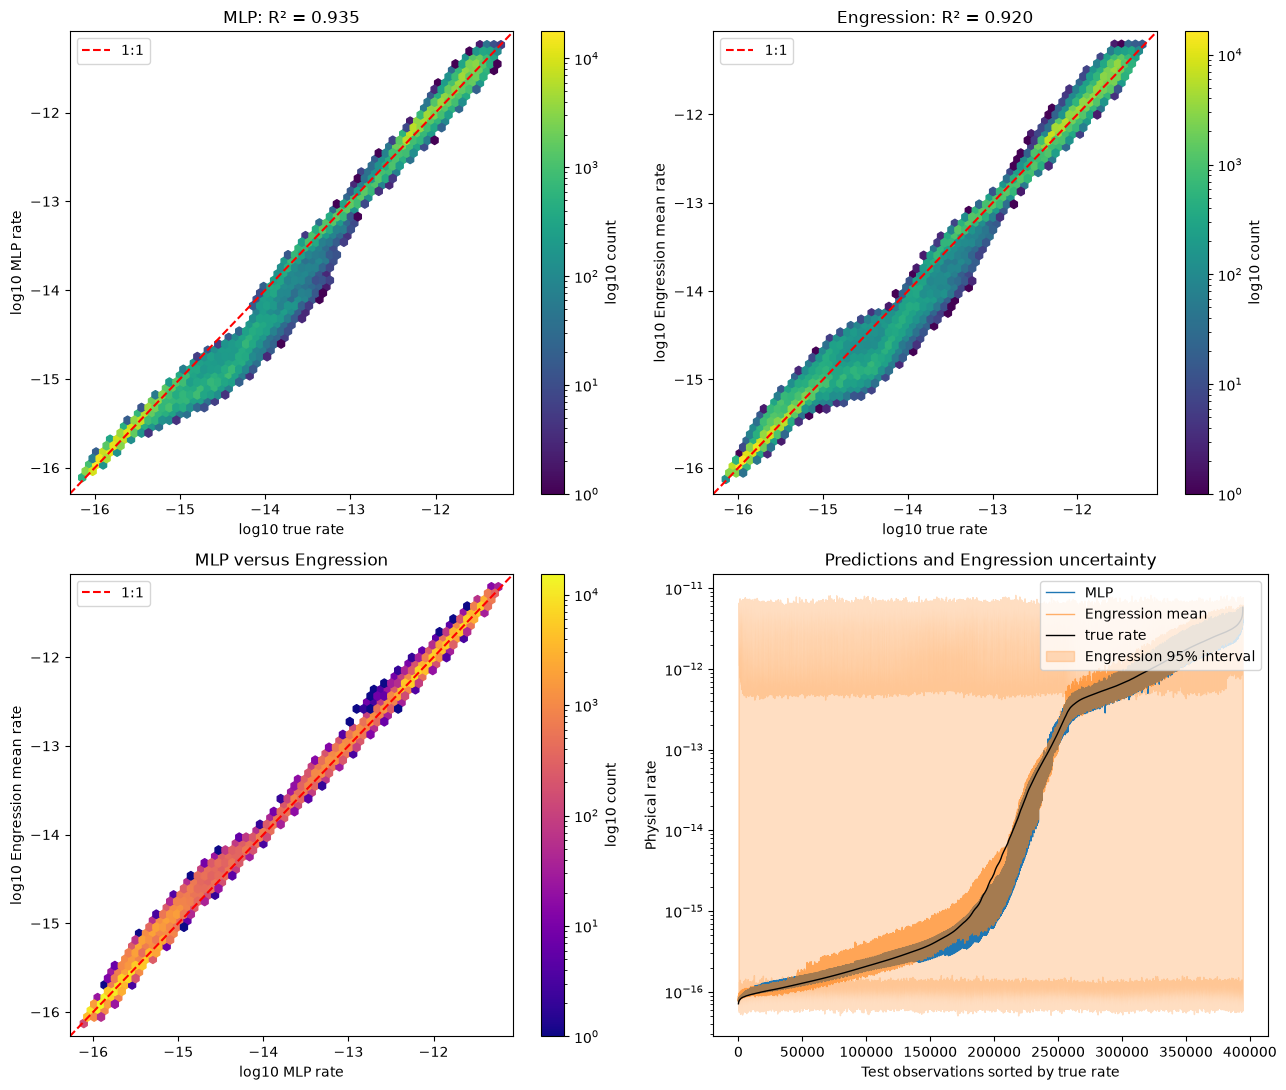

In [40]:
# ---------------------------------------------------------------------
# 5. Plot in log10 physical-rate space
# ---------------------------------------------------------------------
# Rates are nonnegative, so clip only for plotting. This does not alter
# the metrics above.

plot_eps = max(EPS, np.finfo(float).tiny)

true_log = np.log10(np.maximum(y_true, 0.0) + plot_eps)
mlp_log = np.log10(np.maximum(mlp_pred, 0.0) + plot_eps)
eng_log = np.log10(np.maximum(eng_mean, 0.0) + plot_eps)


def common_limits(*arrays):
    values = np.concatenate(arrays)
    finite_values = values[np.isfinite(values)]

    if finite_values.size == 0:
        raise ValueError("No finite values available for plotting.")

    lo = finite_values.min()
    hi = finite_values.max()

    # Avoid a zero-width axis for constant data.
    if lo == hi:
        padding = 0.5
    else:
        padding = 0.03 * (hi - lo)

    return [lo - padding, hi + padding]


fig, ax = plt.subplots(2, 2, figsize=(13, 11))

# MLP versus true rates
mlp_lims = common_limits(true_log, mlp_log)

hb = ax[0, 0].hexbin(true_log, mlp_log, gridsize=60, bins="log", mincnt=1, cmap="viridis")
ax[0, 0].plot(mlp_lims, mlp_lims,"r--", linewidth=1.5, label="1:1")
ax[0, 0].set(xlim=mlp_lims, ylim=mlp_lims,xlabel="log10 true rate", ylabel="log10 MLP rate", title=f"MLP: R² = {mlp_metrics['r2']:.3f}")
ax[0, 0].legend()
fig.colorbar(hb, ax=ax[0, 0], label="log10 count")

# Engression versus true rates
eng_lims = common_limits(true_log, eng_log)

hb = ax[0, 1].hexbin(true_log, eng_log, gridsize=60, bins="log", mincnt=1, cmap="viridis")
ax[0, 1].plot(eng_lims, eng_lims, "r--", linewidth=1.5, label="1:1")
ax[0, 1].set(xlim=eng_lims, ylim=eng_lims, xlabel="log10 true rate", ylabel="log10 Engression mean rate", title=f"Engression: R² = {eng_mean_metrics['r2']:.3f}")
ax[0, 1].legend()
fig.colorbar(hb, ax=ax[0, 1], label="log10 count")

# Direct comparison between model predictions
comparison_lims = common_limits(mlp_log, eng_log)

hb = ax[1, 0].hexbin(mlp_log, eng_log, gridsize=60, bins="log", mincnt=1, cmap="plasma")
ax[1, 0].plot(comparison_lims,comparison_lims, "r--", linewidth=1.5, label="1:1")
ax[1, 0].set(xlim=comparison_lims,ylim=comparison_lims, xlabel="log10 MLP rate", ylabel="log10 Engression mean rate", title="MLP versus Engression")
ax[1, 0].legend()
fig.colorbar(hb, ax=ax[1, 0], label="log10 count")


# Sorted predictions and Engression uncertainty interval
order = np.argsort(y_true)
x = np.arange(len(y_true))

ax[1, 1].plot(x, np.maximum(mlp_pred[order], plot_eps), color="tab:blue", linewidth=1, label="MLP")
ax[1, 1].plot(x, np.maximum(eng_mean[order], plot_eps), color="tab:orange", linewidth=1, label="Engression mean", alpha =0.6)
ax[1, 1].plot(x, np.maximum(y_true[order], plot_eps), color="black", linewidth=1, label="true rate")
ax[1, 1].fill_between(x, np.maximum(eng_q025[order], plot_eps), np.maximum(eng_q975[order], plot_eps), color="tab:orange", alpha=0.25, label="Engression 95% interval")
ax[1, 1].set_yscale("log")
ax[1, 1].set_xlabel("Test observations sorted by true rate")
ax[1, 1].set_ylabel("Physical rate")
ax[1, 1].set_title("Predictions and Engression uncertainty")
ax[1, 1].legend(loc='upper right')


plt.tight_layout()
# plt.savefig("mlp_vs_engression.png", dpi=150, bbox_inches="tight")
plt.show()